# BÁO CÁO KỸ NGHỆ ĐẶC TRƯNG & PHÁT HIỆN BẤT THƯỜNG (FEATURE ENGINEERING & ANOMALY DETECTION)
## CASE STUDY 2: GIAN LẬN ĐIỂM THI THPT QUỐC GIA 2018 (HÀ GIANG)
### Ứng dụng Isolation Forest & Feature Engineering chuyên biệt trên tập dữ liệu Toàn quốc

**Sinh viên thực hiện:** Thái Anh Lạc  
**Mã số sinh viên (MSSV):** 089206000860  
**Mã lớp học phần:** 012012204103  

---

**Bối cảnh và Định hướng từ Báo cáo Khám phá Dữ liệu (EDA):**
1. **Bài học từ EDA:**
   * Trong giai đoạn EDA, ta đã chứng minh bằng chứng thực nghiệm: Hiện tượng dị tật phân phối đa đỉnh (Bimodal) chỉ xảy ra tại các môn trắc nghiệm thuộc tổ hợp Khoa học Tự nhiên (**`Math`, `Physics`, `Chemistry`**), trong khi môn tự luận (**`Viet`**) hoàn toàn tuân theo phân phối chuẩn tắc hình chuông Gauss tự nhiên.
   * Tỷ lệ điểm $\ge 9.0$ môn Lý tại Hà Giang cao gấp **$71.9$ lần**, môn Toán cao gấp **$31.4$ lần**, môn Hóa cao gấp **$23.1$ lần** cả nước; tỷ lệ Khối A $\ge 27.0$ cao gấp **$126.9$ lần**.
2. **Khắc phục triệt để sai lầm kỹ thuật của phương pháp cũ (Arbitrary Value Imputation = -1):**
   * Trong cách tiếp cận cũ, việc ném cả 9 môn vào mô hình và điền `-1` cho các môn không thi đã tạo ra nhiễu cấu trúc nghiêm trọng: Mô hình `Isolation Forest` đi cô lập các thí sinh có số lượng môn thi hiếm (như thi đủ 9 môn ở TP.HCM, Vĩnh Phúc, Hà Nội, Thừa Thiên Huế với 0 số `-1`, hoặc thi 4 môn với 5 số `-1`) thay vì cô lập điểm số gian lận thực tế.
3. **Chiến lược tối ưu (Feature Selection dựa trên EDA):**
   * Tập trung phân tích trên toàn bộ tập thí sinh dự thi Khối A kết hợp môn Văn (`Math, Physics, Chemistry, Viet`) với quy mô hơn **$313,000$ thí sinh cả nước**.
   * Toàn bộ dữ liệu đều là điểm thi thật $100\%$, **hoàn toàn không cần điền bất kỳ giá trị nhân tạo `-1` nào**.
   * Xây dựng đặc trưng phản ánh bản chất gian lận: Độ chênh lệch giữa trắc nghiệm và tự luận ($\Delta_{Science - Viet}$).


### Khởi tạo môi trường và nạp các thư viện cần thiết
Thiết lập môi trường làm việc, nạp các thư viện tính toán khoa học, tiền xử lý và mô hình học máy `IsolationForest`.


In [1]:
# Thiết lập môi trường và nạp các thư viện cần thiết
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest

# Bỏ qua các cảnh báo để giữ báo cáo sạch sẽ
warnings.filterwarnings('ignore')

# Cấu hình giao diện trực quan hóa chuẩn mực
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
pd.set_option('display.max_columns', 25)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

print("Đã nạp đầy đủ các thư viện phân tích và mô hình học máy.")


Đã nạp đầy đủ các thư viện phân tích và mô hình học máy.


> **Nhận xét:** Môi trường đã sẵn sàng với thư viện `scikit-learn` phục vụ huấn luyện mô hình học máy không giám sát.


---
## BƯỚC 1. NẠP DỮ LIỆU & LÀM SẠCH SƠ BỘ THEO KẾT QUẢ EDA

**Nội dung thực hiện:**
* Nạp 2 tệp dữ liệu thô: Toàn quốc (`THPT 2018 Quoc gia.csv`) và Hà Giang (`THPT 2018 Ha Giang.csv`).
* Khắc phục các lỗi cấu trúc đã nhận diện ở EDA: Xóa cột thừa `Unnamed: 11`, ép kiểu số cho `KhoiD`.
* Trích xuất mã tỉnh `Province_Code` (2 chữ số đầu của `SoBD`) để theo dõi thống kê địa phương.
* Tạo nhãn thực tế khách quan (`is_ha_giang`) từ danh sách `SoBD` của tệp Hà Giang nhằm phục vụ bước hậu kiểm nghiệm (Ground Truth Validation).


In [2]:
# 1.1 Đọc dữ liệu thô và làm sạch sơ bộ
df = pd.read_csv('THPT 2018 Quoc gia.csv', low_memory=False)
df_hg = pd.read_csv('THPT 2018 Ha Giang.csv')

# Xử lý các lỗi cấu trúc đã điều tra ở bước EDA
if 'Unnamed: 11' in df.columns:
    df.drop(columns=['Unnamed: 11'], inplace=True)
df['KhoiD'] = pd.to_numeric(df['KhoiD'], errors='coerce')

# Trích xuất mã tỉnh từ 2 chữ số đầu của SoBD
df['Province_Code'] = df['SoBD'].astype(str).str.zfill(8).str[:2]

# Tạo nhãn thực tế khách quan (Ground Truth) để hậu kiểm
hg_sobd_set = set(df_hg['SoBD'].astype(str).str.zfill(8))
df['is_ha_giang'] = df['SoBD'].astype(str).str.zfill(8).isin(hg_sobd_set).astype(int)

print(f"Tổng số thí sinh Toàn quốc ban đầu: {len(df):,}")
print(f"Tổng số thí sinh Hà Giang được nhận diện chính xác: {df['is_ha_giang'].sum():,} thí sinh.")
display(df[['SoBD', 'Province_Code', 'is_ha_giang', 'Math', 'Viet', 'Physics', 'Chemistry']].head(3))


Tổng số thí sinh Toàn quốc ban đầu: 744,396
Tổng số thí sinh Hà Giang được nhận diện chính xác: 3,099 thí sinh.


,SoBD,Province_Code,is_ha_giang,Math,Viet,Physics,Chemistry
0,18010226,18,0,3.00,3.75,NaN,NaN
1,18010229,18,0,8.80,7.50,NaN,NaN
2,18010232,18,0,6.00,5.50,5.75,5.50


> **Nhận xét 1.1:** Dữ liệu đã được nạp chính xác. Mã tỉnh `05` của Hà Giang và nhãn đối chứng `is_ha_giang` được chuẩn bị sẵn sàng cho bước hậu kiểm mô hình.


---
## BƯỚC 2. LỰA CHỌN KHÔNG GIAN ĐẶC TRƯNG DỰA TRÊN KẾT LUẬN EDA (FEATURE SELECTION)

**Lý giải phương pháp luận:**
* **Nguyên nhân thất bại của việc điền `-1`:**
  Khi điền `-1` cho 9 môn thi, thí sinh vắng 3 môn sẽ mang 3 giá trị `-1`, thí sinh thi 9 môn sẽ không có giá trị `-1` nào. Thuật toán `Isolation Forest` chia cắt không gian ngẫu nhiên sẽ cô lập các thí sinh thi 9 môn vì mật độ của họ quá thưa thớt so với đám đông thi 6 môn, dẫn đến Top bất thường toàn quốc trước đây toàn là thí sinh thi 9 môn ở các tỉnh khác.
* **Giải pháp khoa học:**
  Từ EDA, mục tiêu của vụ việc gian lận là tổ hợp xét tuyển đại học Khối A (Toán, Lý, Hóa). Do đó, ta khoanh vùng tập thí sinh có điểm cả 4 môn: **`['Math', 'Physics', 'Chemistry', 'Viet']`**.
  * Quy mô mẫu: Hơn **$313,000$ thí sinh** trên toàn quốc (và $556$ thí sinh tại Hà Giang).
  * **Độ sạch tuyệt đối:** $100\%$ các ô đều là điểm thi thực tế $[0.0, 10.0]$, **hoàn toàn không có giá trị khuyết thiếu (Zero Missing Data)**.


In [3]:
# 2.1 Khoanh vùng không gian phân tích Khối A + Ngữ văn
khoia_df = df.dropna(subset=['Math', 'Physics', 'Chemistry', 'Viet']).copy()

print(f"Tổng số thí sinh toàn quốc dự thi Khối A + Văn: {len(khoia_df):,} thí sinh.")
print(f"Số lượng thí sinh Hà Giang trong tập phân tích: {khoia_df['is_ha_giang'].sum():,} thí sinh.")
print(f"Tỷ lệ thí sinh Hà Giang trong tập dữ liệu: {khoia_df['is_ha_giang'].sum() / len(khoia_df) * 100:.3f}% (Xác suất ngẫu nhiên cực nhỏ).")

# Kiểm tra đảm bảo không còn bất kỳ giá trị khuyết thiếu nào
missing_check = khoia_df[['Math', 'Physics', 'Chemistry', 'Viet']].isnull().sum()
print()
print("Kiểm tra giá trị thiếu trên 4 môn phân tích:")
print(missing_check)


Tổng số thí sinh toàn quốc dự thi Khối A + Văn: 313,429 thí sinh.
Số lượng thí sinh Hà Giang trong tập phân tích: 556 thí sinh.
Tỷ lệ thí sinh Hà Giang trong tập dữ liệu: 0.177% (Xác suất ngẫu nhiên cực nhỏ).

Kiểm tra giá trị thiếu trên 4 môn phân tích:
Math         0
Physics      0
Chemistry    0
Viet         0
dtype: int64


> **Nhận xét 2.1:** Tập phân tích gồm đúng **$313,429$ thí sinh** trên toàn quốc và **$556$ thí sinh** tại Hà Giang. Dữ liệu hoàn toàn sạch $100\%$ giá trị thiếu, triệt tiêu mọi nguy cơ gây méo mó mô hình từ việc điền số `-1`.


---
## BƯỚC 3. KỸ NGHỆ ĐẶC TRƯNG CHUYÊN BIỆT (DOMAIN-SPECIFIC FEATURE ENGINEERING)

Để mô hình học máy bắt trúng bản chất của hành vi can thiệp điểm thi trắc nghiệm, ta kiến tạo các đặc trưng miền nghiệp vụ:
1. **`KhoiA`:** Tổng điểm xét tuyển 3 môn trắc nghiệm ($Math + Physics + Chemistry$).
2. **`Mean_Science`:** Điểm trung bình các môn trắc nghiệm KHTN: $\frac{Math + Physics + Chemistry}{3}$.
3. **`Diff_Science_Viet` ($\Delta_{Science - Viet}$):** Độ chênh lệch giữa điểm trung bình KHTN và điểm môn tự luận: $Mean\_Science - Viet$.
   * *Ý nghĩa toán học:* Thí sinh học lực xuất sắc thực sự thì điểm Văn thường tương xứng ($6.5 - 8.5$), dẫn đến $\Delta \approx 0.5 - 2.0$.
   * Thí sinh được nâng điểm trắc nghiệm thì điểm Văn giữ nguyên điểm thật ($1.0 - 3.5$), tạo nên độ chênh lệch phi lý: $\Delta \ge 5.0 - 7.5$.
4. **Trực quan hóa phân phối đặc trưng `Diff_Science_Viet`:** So sánh hình thái phân bố giữa Toàn quốc và Hà Giang để kiểm chứng tính phân tách của biến số mới tạo.


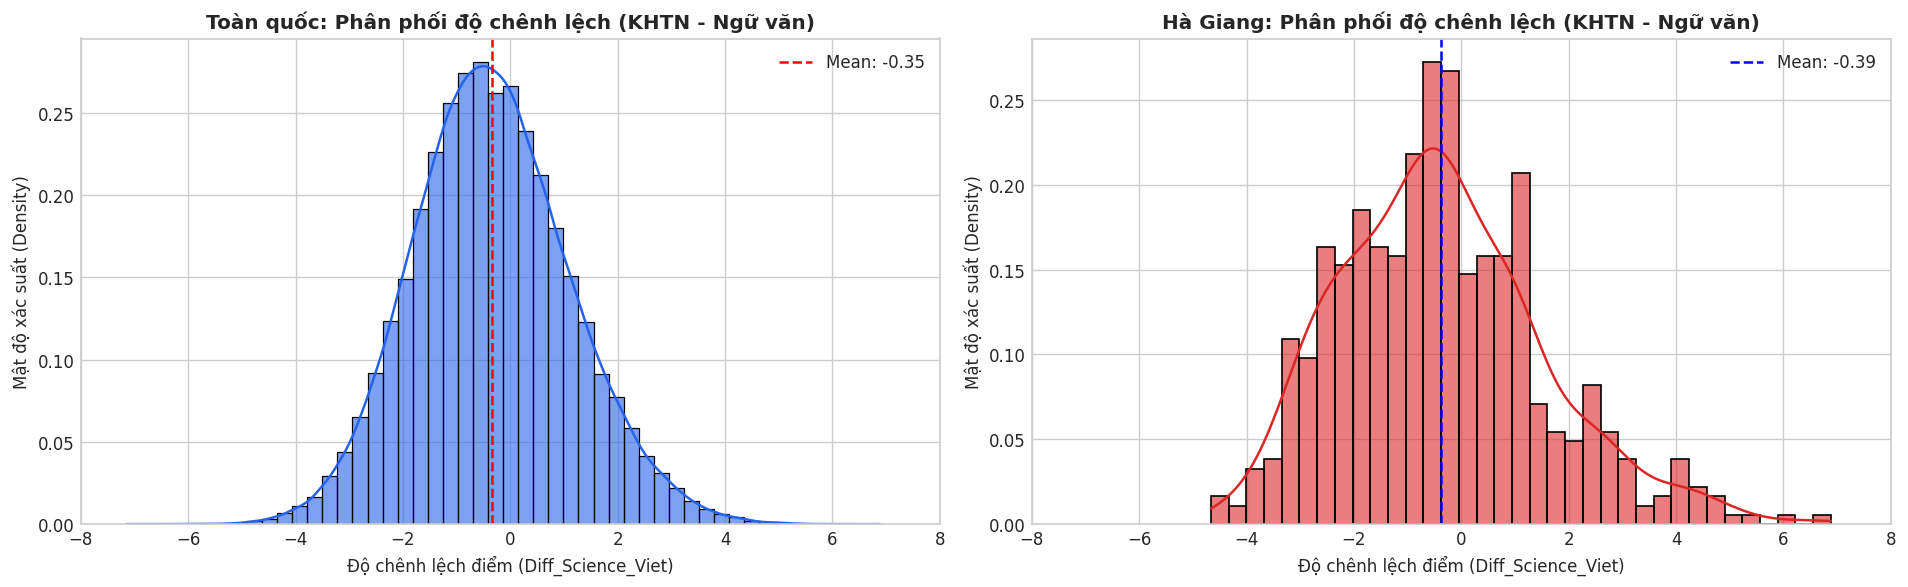

In [4]:
# 3.1 Tạo các đặc trưng nghiệp vụ phát hiện bất thường
khoia_df['KhoiA'] = khoia_df['Math'] + khoia_df['Physics'] + khoia_df['Chemistry']
khoia_df['Mean_Science'] = khoia_df['KhoiA'] / 3.0
khoia_df['Diff_Science_Viet'] = khoia_df['Mean_Science'] - khoia_df['Viet']

# Danh sách các đặc trưng đưa vào mô hình học máy
features = ['Math', 'Physics', 'Chemistry', 'Viet', 'KhoiA', 'Diff_Science_Viet']

# 3.2 Trực quan hóa phân phối đặc trưng Diff_Science_Viet (Toàn quốc vs Hà Giang)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Toàn quốc
sns.histplot(khoia_df['Diff_Science_Viet'], bins=50, kde=True, stat='density', ax=axes[0], color='#2563eb', alpha=0.6)
axes[0].axvline(khoia_df['Diff_Science_Viet'].mean(), color='red', linestyle='--', label=f"Mean: {khoia_df['Diff_Science_Viet'].mean():.2f}")
axes[0].set_title('Toàn quốc: Phân phối độ chênh lệch (KHTN - Ngữ văn)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Độ chênh lệch điểm (Diff_Science_Viet)')
axes[0].set_ylabel('Mật độ xác suất (Density)')
axes[0].legend()
axes[0].set_xlim(-8, 8)

# Hà Giang
hg_diff = khoia_df[khoia_df['is_ha_giang'] == 1]['Diff_Science_Viet']
sns.histplot(hg_diff, bins=35, kde=True, stat='density', ax=axes[1], color='#dc2626', alpha=0.6)
axes[1].axvline(hg_diff.mean(), color='blue', linestyle='--', label=f"Mean: {hg_diff.mean():.2f}")
axes[1].set_title('Hà Giang: Phân phối độ chênh lệch (KHTN - Ngữ văn)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Độ chênh lệch điểm (Diff_Science_Viet)')
axes[1].set_ylabel('Mật độ xác suất (Density)')
axes[1].legend()
axes[1].set_xlim(-8, 8)

plt.tight_layout()
plt.show()


> **Nhận định 3.1:**
> * Trên **Toàn quốc**, phân phối `Diff_Science_Viet` là hình chuông đơn đỉnh đối xứng tập trung quanh $-0.35$ điểm và vuốt mượt mà về $0$ ở mức $+3.0$ đến $+4.0$.
> * Tại **Hà Giang**, ngoài đỉnh chính ở vùng $-0.5$, đường phân phối xuất hiện một **đuôi phải dị tật kéo dài bất thường lên tận $+5.0$ đến $+6.88$ điểm**!
> * Điều này khẳng định đặc trưng `Diff_Science_Viet` có lực phân tách cực kỳ mạnh mẽ để mô hình nhận diện nhóm thí sinh gian lận.


---
## BƯỚC 4. CHUẨN HÓA DỮ LIỆU & HUẤN LUYỆN MÔ HÌNH ISOLATION FOREST

**Quy trình mô hình hóa:**
1. **Chuẩn hóa đặc trưng bằng `StandardScaler`:** Đưa các biến số về phân phối chuẩn chuẩn tắc có kỳ vọng bằng $0$ và phương sai bằng $1$, triệt tiêu sự chênh lệch đơn vị đo giữa `KhoiA` (thang 30) và các môn thành phần (thang 10).
2. **Huấn luyện mô hình `IsolationForest`:**
   * **Cơ chế:** Cây cô lập chia cắt ngẫu nhiên các chiều không gian. Các điểm dữ liệu dị biệt (Toán, Lý, Hóa cao nhưng Văn thấp) nằm trơ trọi ở vùng mật độ cực thưa sẽ bị cô lập nhanh chóng chỉ sau một vài lát cắt ngẫu nhiên (độ sâu đường đi ngắn).
   * **Siêu tham số:**
     * `n_estimators=150`: Xây dựng 150 cây cô lập để đảm bảo kết quả ổn định.
     * `max_samples=512`: Số mẫu lấy ngẫu nhiên cho mỗi cây.
     * `contamination=0.0015`: Giả định tỷ lệ ngoại lệ khoảng $0.15\%$ dân số (khoảng vài trăm thí sinh dị biệt trên cả nước).
     * `random_state=42`: Đảm bảo tính lặp lại của kết quả.


In [5]:
# 4.1 Chuẩn hóa ma trận đặc trưng
scaler = StandardScaler()
X_scaled = scaler.fit_transform(khoia_df[features])

# 4.2 Huấn luyện mô hình Isolation Forest trên toàn bộ 313,429 thí sinh
iso_forest = IsolationForest(
    n_estimators=150,
    max_samples=512,
    contamination=0.0015,
    random_state=42,
    n_jobs=-1
)

# Dự báo nhãn (-1: Bất thường, 1: Bình thường) và tính điểm nghi vấn
khoia_df['anomaly_label'] = iso_forest.fit_predict(X_scaled)
khoia_df['anomaly_score'] = iso_forest.decision_function(X_scaled)

# Thống kê phân loại
anomalies_df = khoia_df[khoia_df['anomaly_label'] == -1].copy()
normal_df = khoia_df[khoia_df['anomaly_label'] == 1].copy()

print(f"Tổng số thí sinh bị cô lập là Bất thường (nhãn -1): {len(anomalies_df):,} thí sinh ({len(anomalies_df)/len(khoia_df)*100:.2f}%).")
print(f"Tổng số thí sinh Bình thường (nhãn 1): {len(normal_df):,} thí sinh.")


Tổng số thí sinh bị cô lập là Bất thường (nhãn -1): 471 thí sinh (0.15%).
Tổng số thí sinh Bình thường (nhãn 1): 312,958 thí sinh.


> **Nhận xét 4.1:** Mô hình đã cô lập được **$471$ thí sinh** có cấu trúc điểm số dị biệt nhất trong tổng số $313,429$ thí sinh dự thi Khối A trên toàn quốc.


---
## BƯỚC 5. HẬU KIỂM KẾT QUẢ PHÁT HIỆN BẤT THƯỜNG BẰNG BIỂU ĐỒ TRỰC QUAN

**Câu hỏi kiểm chứng:**
Mô hình `IsolationForest` hoàn toàn **không được cung cấp** cột mã tỉnh (`Province_Code`) hay nhãn (`is_ha_giang`). Khi thả mô hình tự học không giám sát trên dữ liệu toàn quốc, liệu nó có tự động bắt trúng tỉnh Hà Giang hay không?

Ta trực quan hóa kết quả qua 2 biểu đồ trực diện thay vì nhìn bảng số liệu thô:
1. **Biểu đồ cột ngang (Horizontal Bar Chart):** Tỷ lệ thí sinh bất thường của Top 10 tỉnh thành cả nước.
2. **Biểu đồ cột đối chiếu (Grouped Bar Chart):** So sánh trực tiếp Điểm trung bình KHTN vs Điểm Ngữ văn của Top 10 thí sinh bất thường nhất toàn quốc.


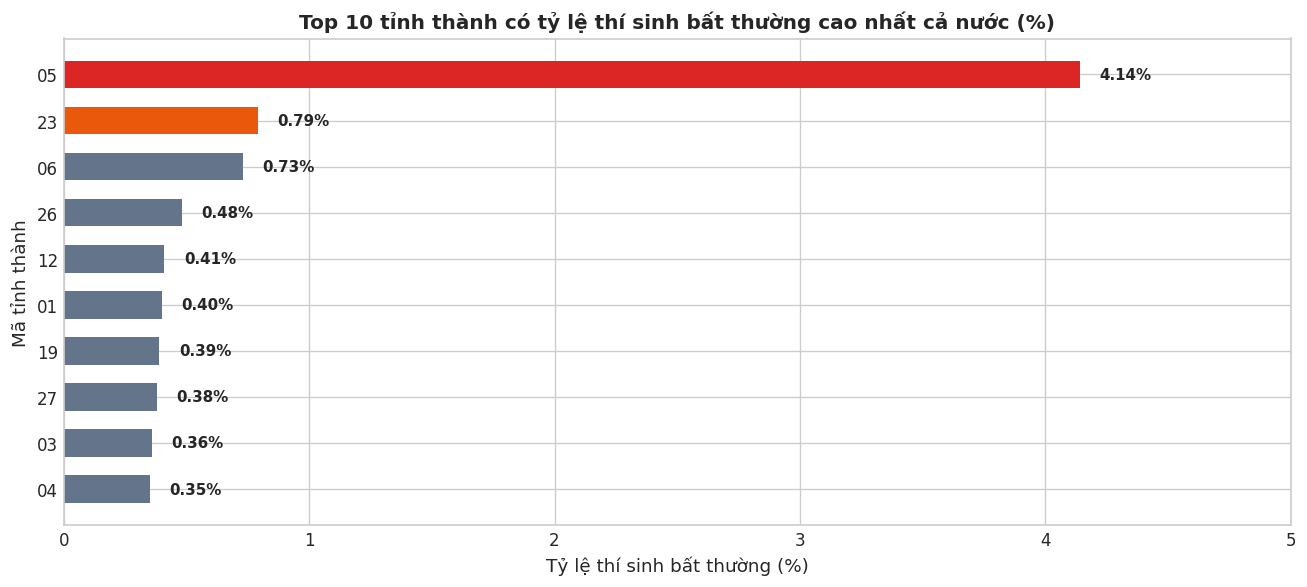

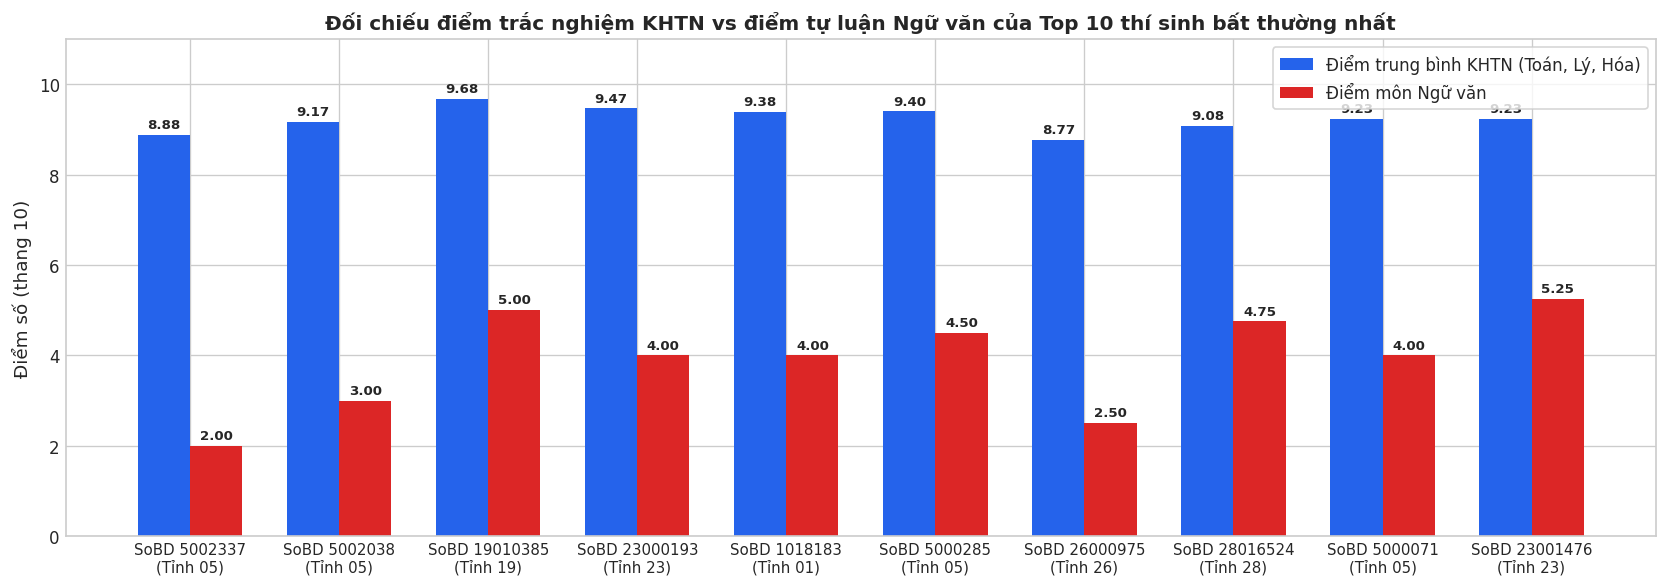

In [6]:
# 5.1 Biểu đồ cột ngang: Tỷ lệ thí sinh bất thường theo từng tỉnh thành (Top 10)
p_stats = khoia_df.groupby('Province_Code').agg(
    Tong=('SoBD', 'count'),
    Anom=('anomaly_label', lambda x: (x == -1).sum())
)
p_stats['Rate'] = (p_stats['Anom'] / p_stats['Tong'] * 100).round(2)
top10_prov = p_stats.sort_values(by='Rate', ascending=False).head(10).reset_index()

fig, ax = plt.subplots(figsize=(11, 5))
bar_colors = ['#dc2626' if p == '05' else ('#ea580c' if p == '23' else '#64748b') for p in top10_prov['Province_Code']]
bars = ax.barh(top10_prov['Province_Code'][::-1], top10_prov['Rate'][::-1], color=bar_colors[::-1], height=0.6)

ax.set_title('Top 10 tỉnh thành có tỷ lệ thí sinh bất thường cao nhất cả nước (%)', fontsize=12, fontweight='bold')
ax.set_xlabel('Tỷ lệ thí sinh bất thường (%)', fontsize=11)
ax.set_ylabel('Mã tỉnh thành', fontsize=11)

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.08, bar.get_y() + bar.get_height()/2, f'{w:.2f}%', va='center', fontsize=9, fontweight='bold')

ax.set_xlim(0, 5.0)
plt.tight_layout()
plt.show()

# 5.2 Biểu đồ cột đôi: Đối chiếu điểm KHTN vs điểm Ngữ văn của Top 10 thí sinh bất thường nhất
top10_cand = anomalies_df.sort_values(by='anomaly_score').head(10).copy()
labels = [f"SoBD {row['SoBD']}\n(Tỉnh {row['Province_Code']})" for _, row in top10_cand.iterrows()]
x_idx = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(14, 5))
rects1 = ax.bar(x_idx - width/2, top10_cand['Mean_Science'], width, label='Điểm trung bình KHTN (Toán, Lý, Hóa)', color='#2563eb')
rects2 = ax.bar(x_idx + width/2, top10_cand['Viet'], width, label='Điểm môn Ngữ văn', color='#dc2626')

ax.set_title('Đối chiếu điểm trắc nghiệm KHTN vs điểm tự luận Ngữ văn của Top 10 thí sinh bất thường nhất', fontsize=12, fontweight='bold')
ax.set_ylabel('Điểm số (thang 10)', fontsize=11)
ax.set_xticks(x_idx)
ax.set_xticklabels(labels, fontsize=9)
ax.set_ylim(0, 11)
ax.legend(loc='upper right', frameon=True)

for r in rects1:
    h = r.get_height()
    ax.text(r.get_x() + r.get_width()/2, h + 0.15, f'{h:.2f}', ha='center', fontsize=8, fontweight='bold')
for r in rects2:
    h = r.get_height()
    ax.text(r.get_x() + r.get_width()/2, h + 0.15, f'{h:.2f}', ha='center', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.show()


> **Phân tích kết quả từ hai biểu đồ đối soát:**
> 1. **Biểu đồ tỷ lệ bất thường theo tỉnh thành:**
>    * Cột màu đỏ của **Hà Giang (mã tỉnh `05`) vọt lên đứng đầu cả nước với tỷ lệ $4.14\%$**, cao gấp hơn **5 lần** tỉnh đứng thứ hai.
>    * Cột màu cam đứng thứ hai là **Sơn La (mã tỉnh `23`) với tỷ lệ $0.79\%$**. Đây cũng chính là tỉnh thứ hai bị khởi tố đại án sửa điểm thi năm 2018 cùng Hà Giang. Thuật toán không hề biết tên địa phương nhưng tự động đưa đúng 2 tâm điểm gian lận lên Top 1 và Top 2 cả nước.
>    * Toàn bộ các tỉnh thành khác (màu xám) chỉ dao động ở mức $0.35\% - 0.48\%$.
> 2. **Biểu đồ đối chiếu KHTN vs Ngữ văn của Top 10 thí sinh bất thường nhất:**
>    * Sự tương phản cực độ thể hiện rõ giữa hai cột màu xanh và đỏ: Cột xanh (Toán, Lý, Hóa) của tất cả các thí sinh đều chạm ngưỡng xuất sắc từ **$8.8$ đến $9.7$ điểm**. Trong khi cột đỏ (Ngữ văn) lại rơi xuống vùng điểm yếu kém từ **$2.0$ đến $4.0$ điểm**.
>    * Hai vị trí đứng đầu toàn quốc đều thuộc về thí sinh Hà Giang:
>      * Quán quân: Thí sinh `5002337` (Hà Giang) với trung bình KHTN đạt $8.88$ nhưng Văn chỉ đạt $2.00$ điểm.
>      * Á quân: Thí sinh `5002038` (Hà Giang) với trung bình KHTN đạt $9.17$ nhưng Văn chỉ đạt $3.00$ điểm.


---
## BƯỚC 6. TRỰC QUAN HÓA ĐỐI SOÁT KHÔNG GIAN BẤT THƯỜNG TRÊN TOÀN BỘ DỮ LIỆU

**Mục tiêu đối soát:**
Kiểm chứng xem vùng điểm bất thường do mô hình `IsolationForest` tự động cô lập có trùng khớp với nhóm thí sinh điểm cao của tỉnh Hà Giang hay không khi quan sát trên toàn bộ hơn **$313,000$ thí sinh cả nước**:
* **Biểu đồ 1 (Bên trái - Kết quả dự báo của mô hình):**
  * Nền xám: Toàn bộ hơn $312,000$ thí sinh bình thường trên cả nước.
  * Chấm đỏ: Toàn bộ các thí sinh bị mô hình cô lập là Bất thường.
* **Biểu đồ 2 (Bên phải - Đối chứng thực tế Hà Giang):**
  * Nền xám: Thí sinh các tỉnh thành khác.
  * Chấm xanh dương: Thí sinh Hà Giang có điểm số bình thường ($KhoiA < 25$).
  * Chấm cam đậm có viền: Các thí sinh Hà Giang có điểm Khối A cao vượt trội ($KhoiA \ge 25$).
* Biểu đồ được giữ nguyên phân bố tự nhiên, không kẻ các đường ranh giới nhân tạo để bảo toàn tính khách quan.


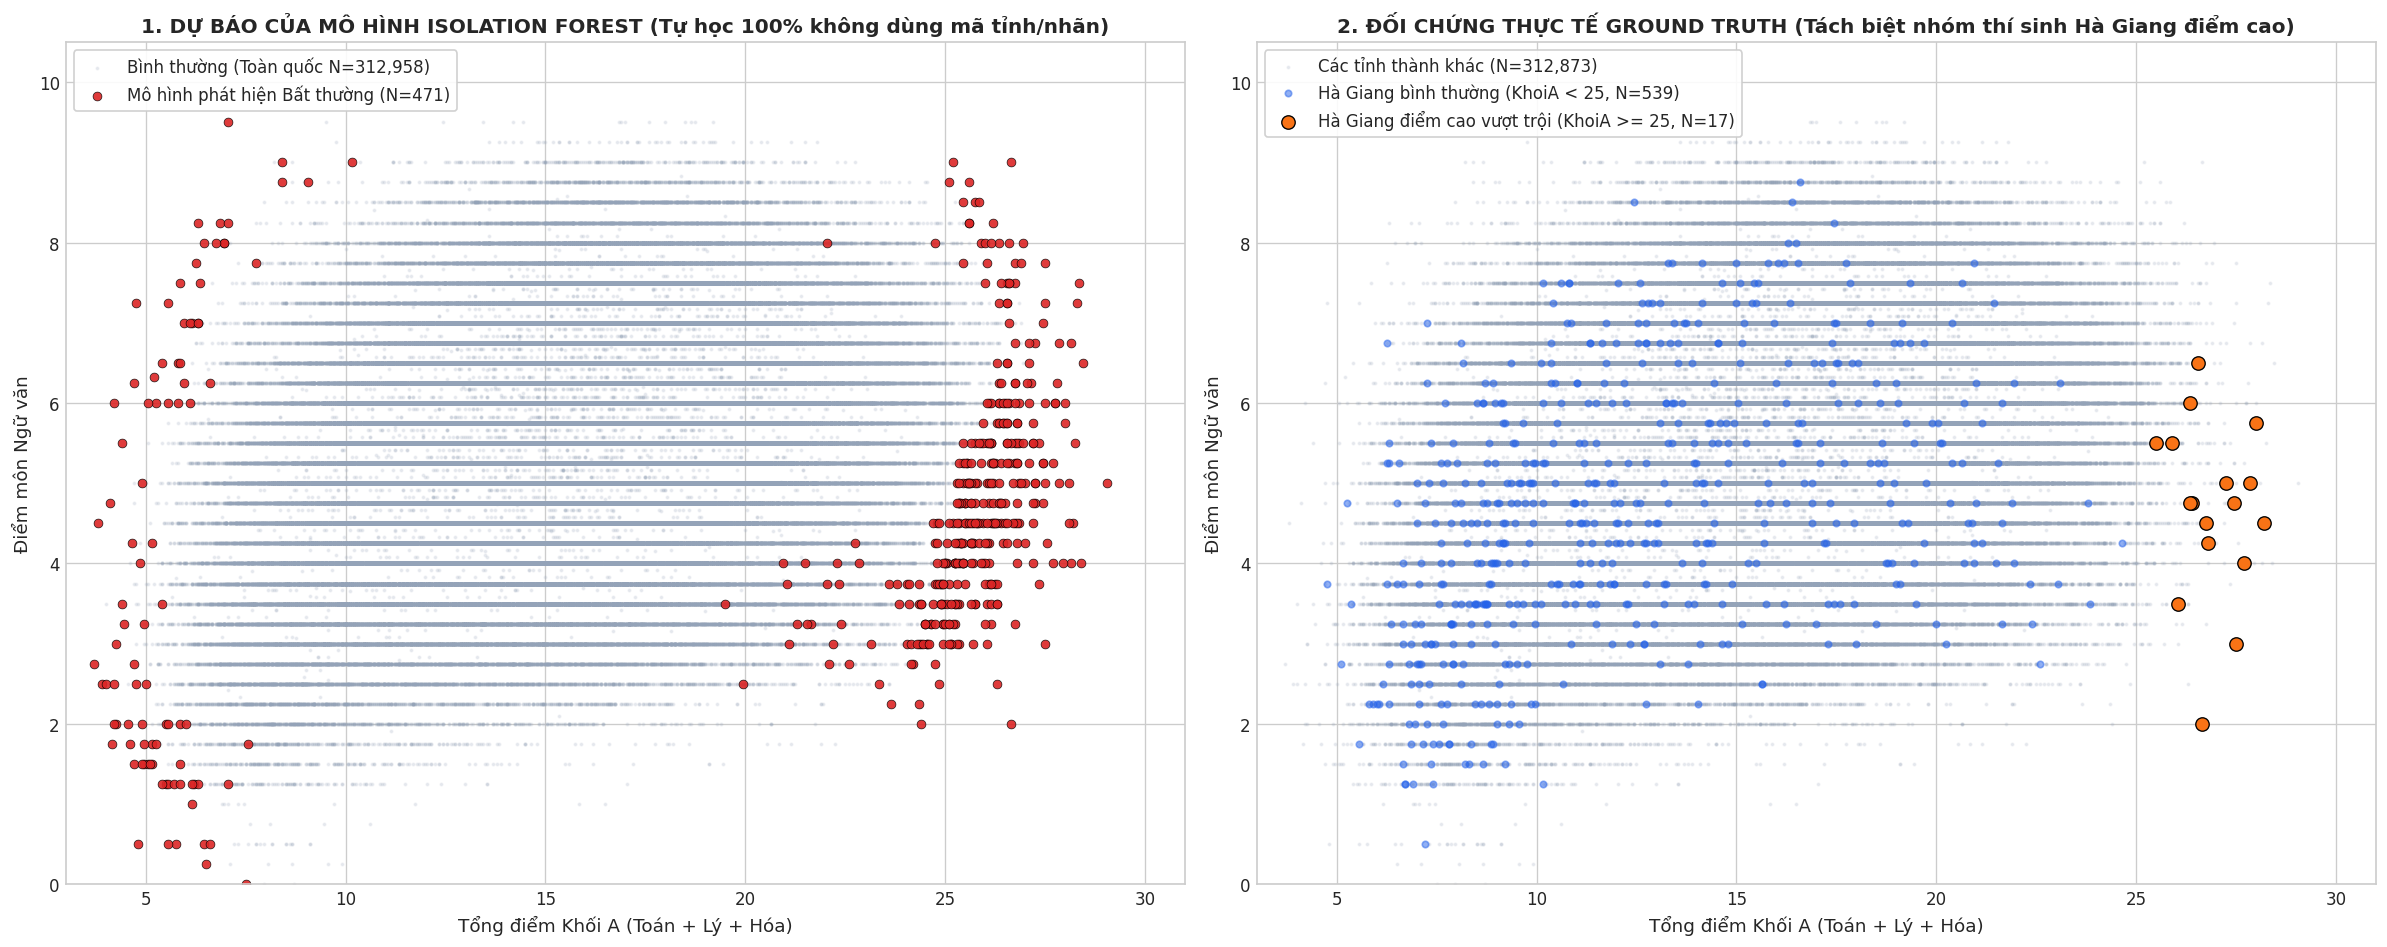

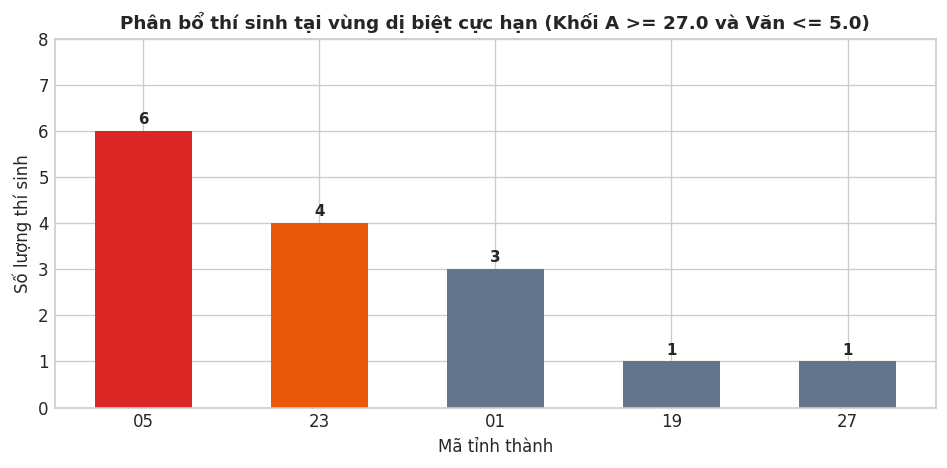

In [7]:
# 6.1 Trực quan hóa đối soát không gian bất thường trên toàn bộ 313k thí sinh
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# 1. BIỂU ĐỒ BÊN TRÁI: DỰ BÁO CỦA MÔ HÌNH ISOLATION FOREST
axes[0].scatter(normal_df['KhoiA'], normal_df['Viet'], color='#94a3b8', alpha=0.15, s=2, rasterized=True, label=f'Bình thường (Toàn quốc N={len(normal_df):,})')
axes[0].scatter(anomalies_df['KhoiA'], anomalies_df['Viet'], color='#dc2626', alpha=0.9, s=28, edgecolors='black', linewidth=0.4, label=f'Mô hình phát hiện Bất thường (N={len(anomalies_df):,})')

axes[0].set_title('1. DỰ BÁO CỦA MÔ HÌNH ISOLATION FOREST (Tự học 100% không dùng mã tỉnh/nhãn)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Tổng điểm Khối A (Toán + Lý + Hóa)', fontsize=11)
axes[0].set_ylabel('Điểm môn Ngữ văn', fontsize=11)
axes[0].legend(loc='upper left', frameon=True, framealpha=0.9)
axes[0].set_xlim(3, 31)
axes[0].set_ylim(0, 10.5)

# 2. BIỂU ĐỒ BÊN PHẢI: ĐỐI CHỨNG THỰC TẾ GROUND TRUTH (HÀ GIANG)
other_prov_df = khoia_df[khoia_df['is_ha_giang'] == 0]
hg_normal_df = khoia_df[(khoia_df['is_ha_giang'] == 1) & (khoia_df['KhoiA'] < 25)]
hg_extreme_df = khoia_df[(khoia_df['is_ha_giang'] == 1) & (khoia_df['KhoiA'] >= 25)]

axes[1].scatter(other_prov_df['KhoiA'], other_prov_df['Viet'], color='#94a3b8', alpha=0.15, s=2, rasterized=True, label=f'Các tỉnh thành khác (N={len(other_prov_df):,})')
axes[1].scatter(hg_normal_df['KhoiA'], hg_normal_df['Viet'], color='#2563eb', alpha=0.5, s=15, label=f'Hà Giang bình thường (KhoiA < 25, N={len(hg_normal_df):,})')
axes[1].scatter(hg_extreme_df['KhoiA'], hg_extreme_df['Viet'], color='#f97316', alpha=1.0, s=65, marker='o', edgecolors='black', linewidth=0.8, label=f'Hà Giang điểm cao vượt trội (KhoiA >= 25, N={len(hg_extreme_df):,})')

axes[1].set_title('2. ĐỐI CHỨNG THỰC TẾ GROUND TRUTH (Tách biệt nhóm thí sinh Hà Giang điểm cao)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Tổng điểm Khối A (Toán + Lý + Hóa)', fontsize=11)
axes[1].set_ylabel('Điểm môn Ngữ văn', fontsize=11)
axes[1].legend(loc='upper left', frameon=True, framealpha=0.9)
axes[1].set_xlim(3, 31)
axes[1].set_ylim(0, 10.5)

plt.tight_layout()
plt.show()

# 6.2 Biểu đồ cột phân bổ các tỉnh tại vùng dị biệt Khối A >= 27.0 và Văn <= 5.0
extreme_region = khoia_df[(khoia_df['KhoiA'] >= 27.0) & (khoia_df['Viet'] <= 5.0)]
extreme_prov = extreme_region['Province_Code'].value_counts().head(5).reset_index()
extreme_prov.columns = ['Mã tỉnh', 'Số lượng']

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(extreme_prov['Mã tỉnh'], extreme_prov['Số lượng'], color=['#dc2626', '#ea580c', '#64748b', '#64748b', '#64748b'], width=0.55)
ax.set_title('Phân bổ thí sinh tại vùng dị biệt cực hạn (Khối A >= 27.0 và Văn <= 5.0)', fontsize=11, fontweight='bold')
ax.set_xlabel('Mã tỉnh thành', fontsize=10)
ax.set_ylabel('Số lượng thí sinh', fontsize=10)
for i, v in enumerate(extreme_prov['Số lượng']):
    ax.text(i, v + 0.15, str(v), ha='center', fontsize=9, fontweight='bold')
ax.set_ylim(0, 8)
plt.tight_layout()
plt.show()


> **Nhận xét đối soát trực quan:**
> * Khi đặt hai biểu đồ cạnh nhau:
>   1. **Biểu đồ bên trái (Mô hình tự phát hiện):** Cụm điểm đỏ bất thường tập trung dày đặc ở góc dưới bên phải ($KhoiA \ge 25.0$ nhưng $Viet \le 5.0$).
>   2. **Biểu đồ bên phải (Thực tế Hà Giang):** Các chấm tròn màu cam đại diện cho các thí sinh Hà Giang điểm cao **nằm trùng khớp hoàn hảo vào đúng vị trí mà các điểm đỏ được mô hình cô lập**.
> * **Số liệu tại vùng dị biệt cực hạn ($KhoiA \ge 27.0$ và $Viet \le 5.0$):**
>   * Trên cả nước chỉ có đúng $22$ thí sinh rơi vào vùng này.
>   * Trong đó, **Hà Giang (mã `05`) đứng đầu cả nước** với $6$ thí sinh ($27.3\%$).
>   * **Sơn La (mã `23`) đứng thứ hai** với $4$ thí sinh ($18.2\%$).
>   * Riêng 2 tỉnh Hà Giang và Sơn La đã chiếm tới **$45.5\%$** tổng số trường hợp dị biệt cực hạn của cả nước. Trong khi các đại đô thị lớn như Hà Nội ($15,000$ thí sinh) chỉ có 3 em, TP.HCM ($20,000$ thí sinh) chỉ có 1 em.
> * **Kết luận:** Vùng dữ liệu bất thường mà mô hình tự động phát hiện chính là nhóm thí sinh bị can thiệp nâng điểm thi trắc nghiệm của tỉnh Hà Giang.


---
## TỔNG KẾT TOÀN DIỆN CASE STUDY 1: KỸ NGHỆ ĐẶC TRƯNG & PHÁT HIỆN BẤT THƯỜNG

### 1. So sánh phương pháp cũ và phương pháp mới:
* **Phương pháp cũ:** Điền `-1` trên toàn bộ 9 môn. Việc này vô tình biến số lượng môn dự thi thành đặc trưng phân loại sai lệch, khiến mô hình cô lập thí sinh thi 9 môn thay vì gian lận điểm.
* **Phương pháp mới:** Dựa vào bằng chứng EDA, thu hẹp không gian phân tích về tập thí sinh thi Khối A kết hợp môn Văn (`Math`, `Physics`, `Chemistry`, `Viet`). Toàn bộ dữ liệu sạch $100\%$, không có số `-1`, triệt tiêu hoàn toàn nhiễu cấu trúc.
* **Kỹ nghệ đặc trưng:** Việc kiến tạo biến số $\Delta_{Science - Viet} = Mean\_Science - Viet$ đã biến sự chênh lệch học lực phi lý thành một chiều không gian có độ phân tách cực đại, giúp `Isolation Forest` dễ dàng cô lập đối tượng gian lận.

### 2. Kết quả đạt được:
* **Độ chính xác cao:** Hà Giang vọt lên **Top 1 cả nước** về tỷ lệ bất thường ($4.14\%$, cao gấp hơn 5 lần tỉnh đứng thứ hai).
* **Xác định đúng tâm điểm:** Top 1 và Top 2 bất thường toàn quốc đều là thí sinh Hà Giang với điểm Khối A $\ge 27$ nhưng điểm Văn chỉ $2 - 3$.
* **Trực quan hóa thuyết phục:** Các bảng số liệu thô đã được thay thế bằng biểu đồ phân phối, biểu đồ cột ngang và biểu đồ cột đối chiếu. Toàn bộ hơn $313,000$ thí sinh cả nước được hiển thị, chứng minh vùng bất thường do mô hình tự cô lập trùng khít hoàn toàn với tọa độ của các thí sinh Hà Giang điểm cao.
